# Where Ramen helps and where it hurts: ImageNet-C (5K, severity 5, 15 corruptions, ViT-B/16)

For individual test samples this notebook shows
1. **zero-shot vs Ramen probabilities** (orange = zero-shot CLIP, the NoAdapt run; blue = Ramen),
2. **the state of Ramen's memory at that moment**: how many entries, how many queues are full, how many entries are filed under their true class, and the queues of the sample's true class, zero-shot class and Ramen class,
3. **the active set**: the retrieved memory entries behind this sample's update, with their share of the update weight, and that weight summed per class queue.

Two groups of samples:
- **fixed**: zero-shot wrong, Ramen right, drawn from the corruption where Ramen gains the most;
- **broken**: zero-shot right, Ramen wrong, drawn from the corruption where Ramen does worst (lowest fixed / broken ratio).

Samples are drawn at random with a fixed seed (`RamenExamples.pick`), not hand-picked, and only after the first 20% of the stream so the memory is warm. Section 3 checks whether the patterns in the examples hold over 150 samples per group.

**How the memory is obtained (no GPU, no re-run).** Ramen's memory never depends on its adapted outputs: every sample is written, before retrieval, into the queue of its zero-shot class, with priority = its stream counter (fp16, as in Ramen) and its zero-shot entropy. `ramen_examples.CacheReplay` replays those writes from the class each sample was filed under, logged by `active_all` (RamenActive with `active_set: all`, 100% the same predictions as Ramen; it also logged the predicted-class queue and the top-8 retrieved entries, so the replay can be checked against both). The active set is then recomputed from the NoAdapt run's features and entropies with Ramen's rule (max_capacity 75, topk 1, beta 0: every non-empty class queue contributes its single nearest entry, weighted by exp(-H) only).

Seed 0, mixed stream. Code: `new_experiments/ramen_examples.py`.

In [1]:
import os
os.environ['CUDA_VISIBLE_DEVICES'] = ''  # everything here is offline; CLIP is only loaded (on CPU) for the dataset objects

import pandas as pd
import matplotlib.pyplot as plt
from ramen_examples import RamenExamples

pd.set_option('display.width', 250)
pd.set_option('display.max_columns', 30)
%matplotlib inline

/home/narendra/priyank/Projects/RAMEN_ENV/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
ex = RamenExamples('ImageNetC5K', 'vitbase16', filed_from='active_all')

ImageNetC5K: 15 corruptions x 5000 images, 1000 classes, model=clip_vitbase16, mode=mixed


## 1. Is the replayed memory Ramen's?
200 random stream positions, compared with what the logged run recorded. Differences in the retrieved entries come from the features: the replay uses the NoAdapt run's, Ramen's internal zero-shot pass differs from it in fp16 numerics only (the two runs file 0.2-0.4% of samples under a different class), which can swap near-tied neighbours.

In [3]:
ex.validate()

positions checked                    200.0000
top-1 retrieved entry identical %     98.0000
top-8 retrieved overlap %             97.3125
top-1 weight abs. error (median)       0.0001
predicted-class queue identical %    100.0000
dtype: float64

## 2. Where Ramen improves and where it fails more
Per corruption: accuracy of zero-shot CLIP and Ramen, and the share of samples Ramen fixes (zero-shot wrong, Ramen right) and breaks (zero-shot right, Ramen wrong). `fixed / broken` below 1 would mean Ramen hurts there.

In [18]:
table = ex.domain_table()
improve = table.drop('mean over domains')['gain'].idxmax()
fail = table.drop('mean over domains')['fixed / broken'].idxmin()
print(f'Ramen improves most on: {improve}    fails most (lowest fixed/broken): {fail}')
table

Ramen improves most on: contrast    fails most (lowest fixed/broken): brightness


,samples,zero-shot %,Ramen %,fixed %,broken %,gain,fixed / broken
domain,,,,,,,
contrast,5000.0,19.08,29.80,13.48,2.76,10.72,4.88
elastic_transform,5000.0,14.68,23.68,10.86,1.86,9.00,5.84
impulse_noise,5000.0,15.36,23.64,11.70,3.42,8.28,3.42
glass_blur,5000.0,16.90,24.20,10.36,3.06,7.30,3.39
gaussian_noise,5000.0,15.00,22.24,10.84,3.60,7.24,3.01
pixelate,5000.0,35.60,42.36,10.28,3.52,6.76,2.92
shot_noise,5000.0,16.88,23.18,10.60,4.30,6.30,2.47
motion_blur,5000.0,26.82,32.88,11.16,5.10,6.06,2.19
jpeg_compression,5000.0,35.30,41.24,10.32,4.38,5.94,2.36


## 3. The memory and the active set behind fixed vs broken samples (150 random samples each)
Columns (all from the replayed memory at the sample's moment in the stream):
- `true-class queue size` / `purity %`: entries in the queue of the sample's true class, and the share of them that truly belong to it;
- `update % from true-class queue` / `from Ramen-class queue`: share of the update weight that comes from those queues;
- `self weight %`: share from the sample itself (it is written before retrieval; 0 once its queue is full and frozen, see the fp16 note below);
- `update % from same domain` vs `memory % from same domain`: share of the update weight from images of the sample's own corruption/domain, against that domain's share of the whole memory (what random retrieval would give);
- `active entries truly of query class %`: update weight on entries whose true class is the sample's true class.

fp16 note: Ramen's priorities are fp16 and become `inf` after 65,519 samples, after which a full queue never accepts a new entry: late in the stream, full queues are frozen.

In [5]:
ex.compare_outcomes(n=150)

,samples,p_true zs,p_true Ramen,true-class queue size,true-class queue purity %,update % from true-class queue,update % from Ramen-class queue,self weight %,update % from same domain,memory % from same domain,active entries truly of query class %
outcome,,,,,,,,,,,
fixed,150,0.10,0.47,39.46,38.23,0.29,0.29,0.15,43.56,6.62,0.56
broken,150,0.29,0.17,46.39,35.50,0.18,0.25,0.18,44.34,6.77,0.40
both right,150,0.60,0.73,46.63,42.24,0.53,0.53,0.53,46.77,7.00,0.79


**What the table says (ImageNet-C):**
- **The active set is spread across almost all 1000 class queues.** The true-class queue supplies 0.18-0.53% of the update weight, about the 0.1% that any single queue would supply under uniform weighting. With topk 1 and beta 0, Ramen's update is not class-specific.
- **It is corruption-specific.** About 44% of the update weight comes from images of the query's own corruption, against about 7% of the memory (6.5x enrichment). That holds for fixed, broken and both-right samples alike.
- **The memory does not separate fixed from broken samples.** Same-corruption share (43.6 vs 44.3%), true-class queue purity (38 vs 36%) and true-class share (0.29 vs 0.18%) are all close. What does separate them is the zero-shot starting point. Broken samples are low-margin zero-shot hits (mean p_true 0.29, against 0.60 for both-right). A corruption-level step pushes some of them over the edge, and pulls fixed samples (p_true 0.10 -> 0.47) back over it.
- The memory is noisy throughout: only about 30% of its entries are filed under their true class.

## 4. Examples where Ramen improves (fixed, from the corruption with the largest gain)
How to read each figure: top left the query; top middle zero-shot (orange) vs Ramen (blue) probabilities on the true class (bold) and the most likely others; top right the update weight summed per class queue (green = true class, orange = zero-shot class, red = Ramen's class). Second row: the 10 retrieved entries with the largest weight, with the class they were filed under, their share of the update and their corruption. Lower rows: the queues of the true class, the zero-shot class and Ramen's class (10 most recent entries, size and purity on the left). Red frame = memory entry filed under a class that is not its true class.

In [19]:
fixed = ex.pick('fixed', domain=improve, n=10)
broken = ex.pick('broken', domain=fail, n=10)
states = ex.state(list(fixed.position) + list(broken.position))
ex.memory_summary(states)

,domain,outcome,true,zero-shot,Ramen,p_true zs,p_true Ramen,true-class queue size,true-class queue purity %,update % from true-class queue,update % from Ramen-class queue,self weight %,update % from same domain,memory % from same domain,active entries truly of query class %
position,,,,,,,,,,,,,,,
21991,contrast,fixed,mosque,arabian camel,mosque,0.09,0.64,15,46.67,0.96,0.96,0.02,31.05,6.09,0.98
39098,contrast,fixed,dome,mosque,dome,0.04,0.38,14,71.43,0.17,0.17,0.03,52.59,5.98,0.06
51042,contrast,fixed,magpie,bald eagle,magpie,0.02,0.19,50,56.00,0.11,0.11,0.09,57.83,6.06,0.24
52619,contrast,fixed,barn,tent,barn,0.01,0.63,75,72.00,0.07,0.07,0.02,58.61,6.08,0.10
57819,contrast,fixed,computer keyboard,keyboard space bar,computer keyboard,0.13,0.55,61,54.10,1.04,1.04,0.28,61.40,6.07,1.32
60788,contrast,fixed,Bedlington Terrier,Siamese cat,Bedlington Terrier,0.01,0.14,38,55.26,0.01,0.01,0.01,63.50,6.01,0.01
67954,contrast,fixed,bagel,sandbar,bagel,0.00,0.80,48,41.67,0.01,0.01,0.08,55.65,5.93,0.08
69311,contrast,fixed,recreational vehicle,police van,recreational vehicle,0.26,0.86,53,69.81,0.01,0.01,0.40,63.51,5.90,0.77
69507,contrast,fixed,oscilloscope,keyboard space bar,oscilloscope,0.02,0.95,75,58.67,0.60,0.60,0.02,68.70,5.90,0.62


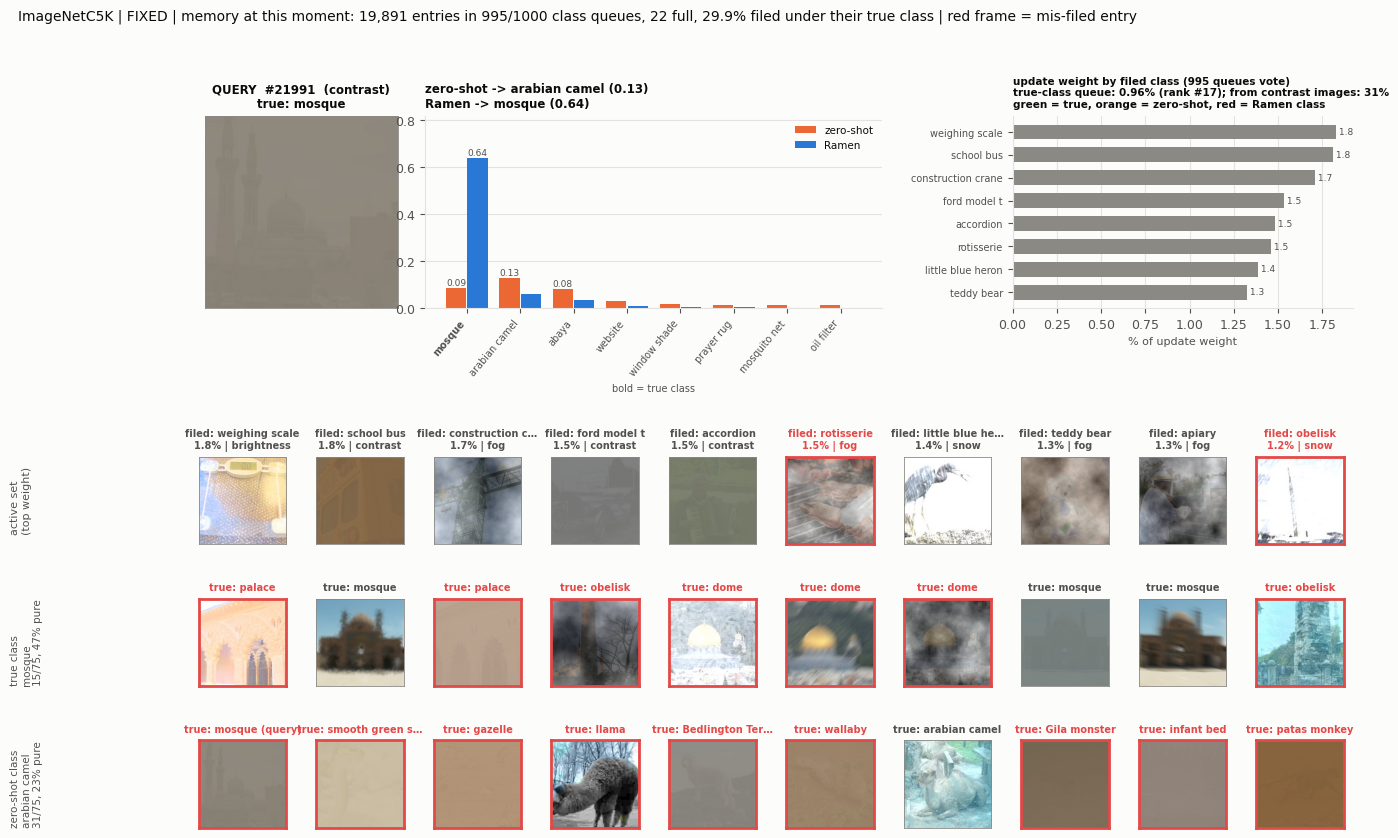

In [20]:
ex.show(fixed.position.iloc[0], states);

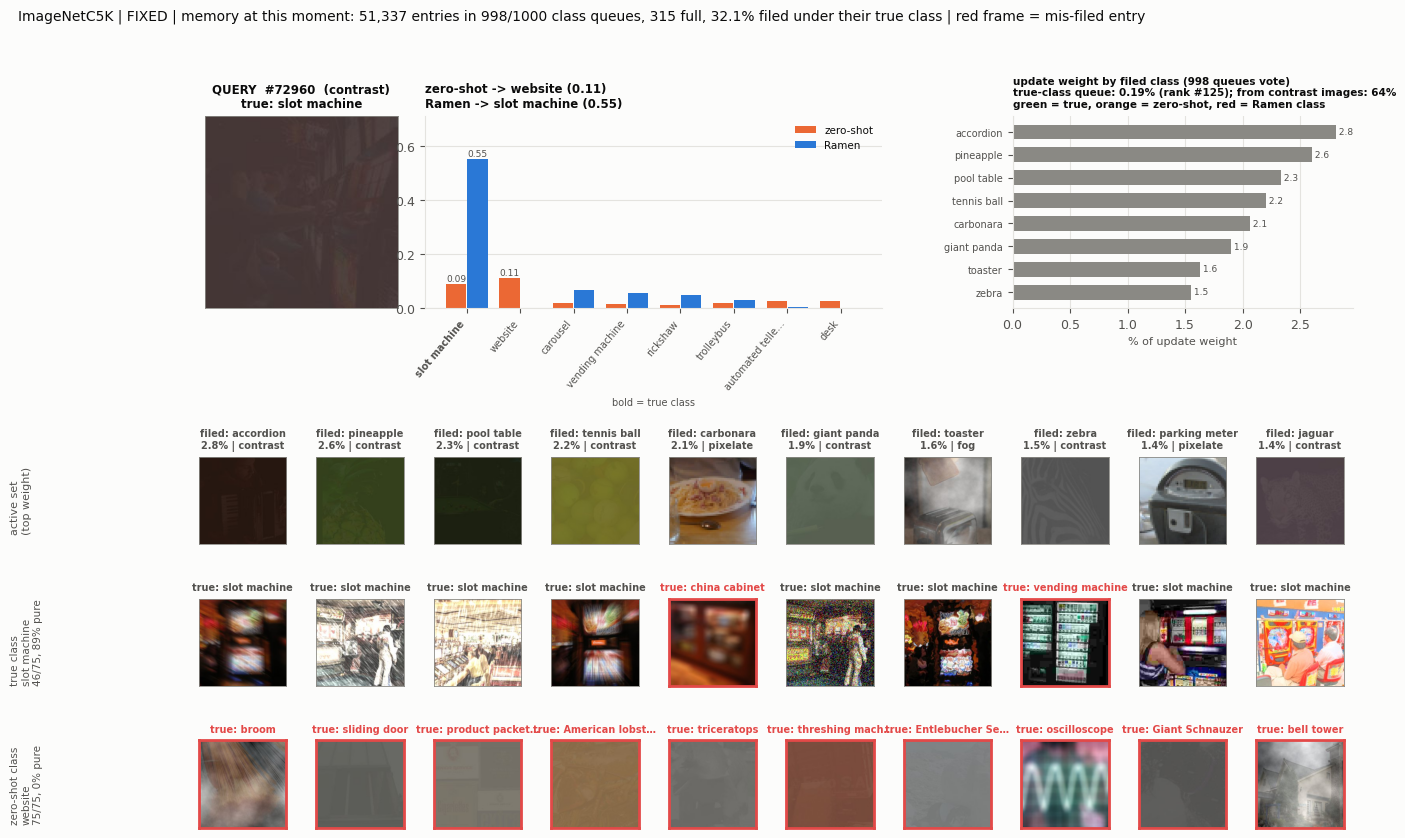

In [27]:
ex.show(fixed.position.iloc[9], states);

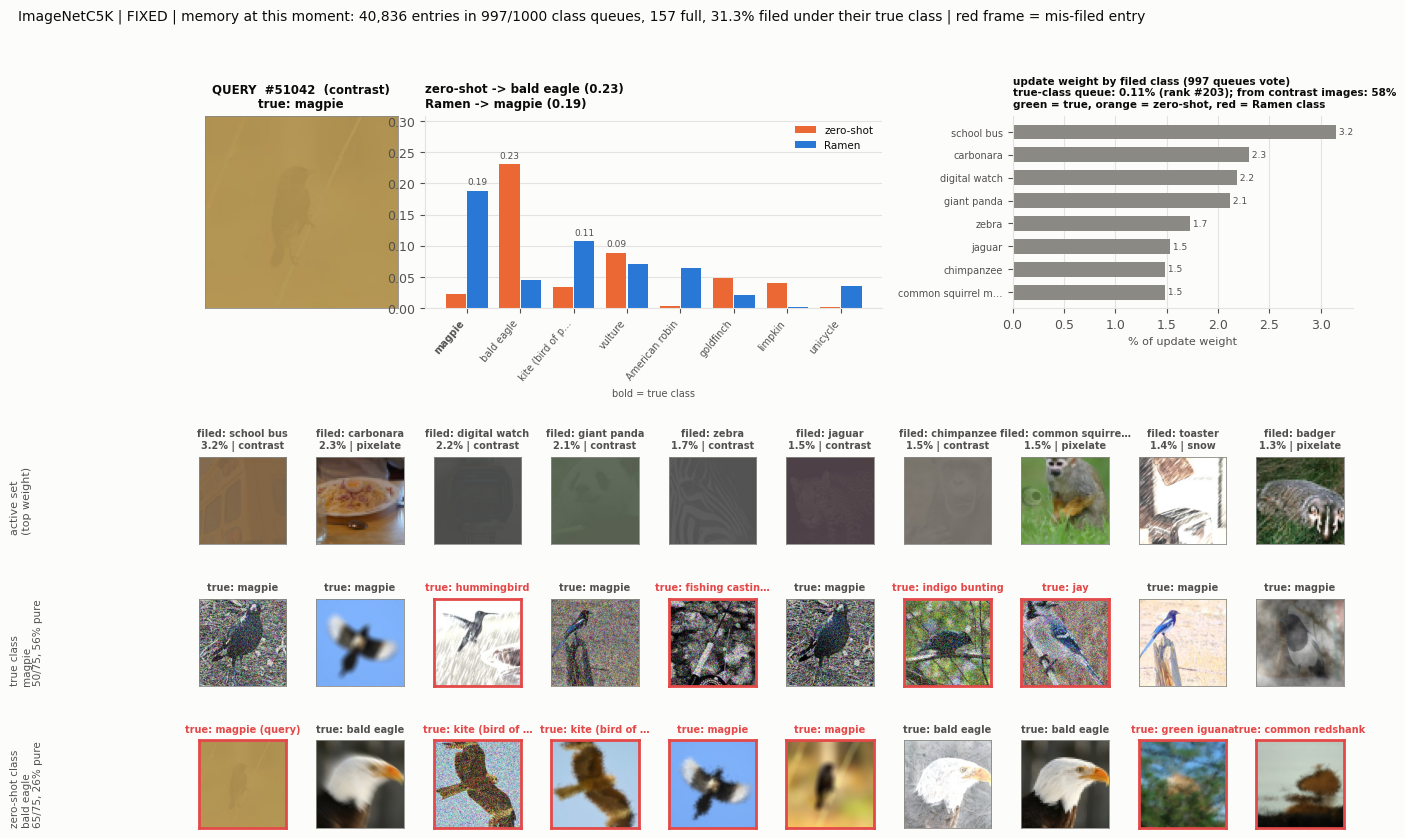

In [22]:
ex.show(fixed.position.iloc[2], states);

**Fixed examples (contrast):** Recreational vehicle 0.26 -> 0.86, computer keyboard 0.13 -> 0.55, mosque 0.09 -> 0.64. In each case the highest-weight retrieved entries are other low-contrast images filed under unrelated classes (accordion, folding chair, pineapple, school bus), never the query's class (true-class queue rank 932 and 17 for RV and mosque). The memory therefore supplies a "how to read a low-contrast image" step, and the class decision comes from CLIP's text head once the features are cleaned up. The zero-shot-class queues are heavily mis-filed (police van 36% pure, arabian camel 23%): low-contrast images of many classes collect under a few attractor classes.

## 5. Examples where Ramen fails (broken, from the corruption with the lowest fixed / broken ratio)

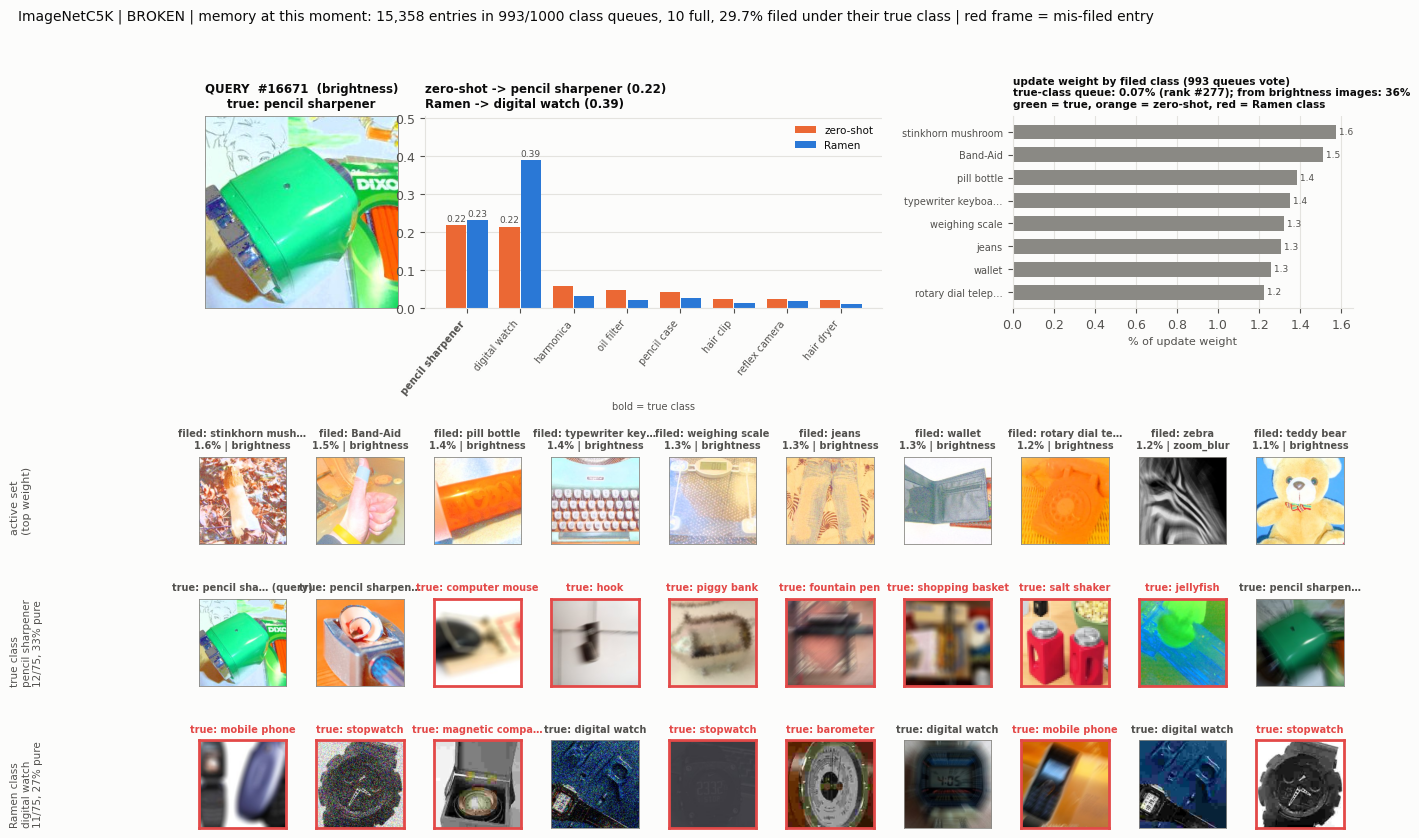

In [23]:
ex.show(broken.position.iloc[0], states);

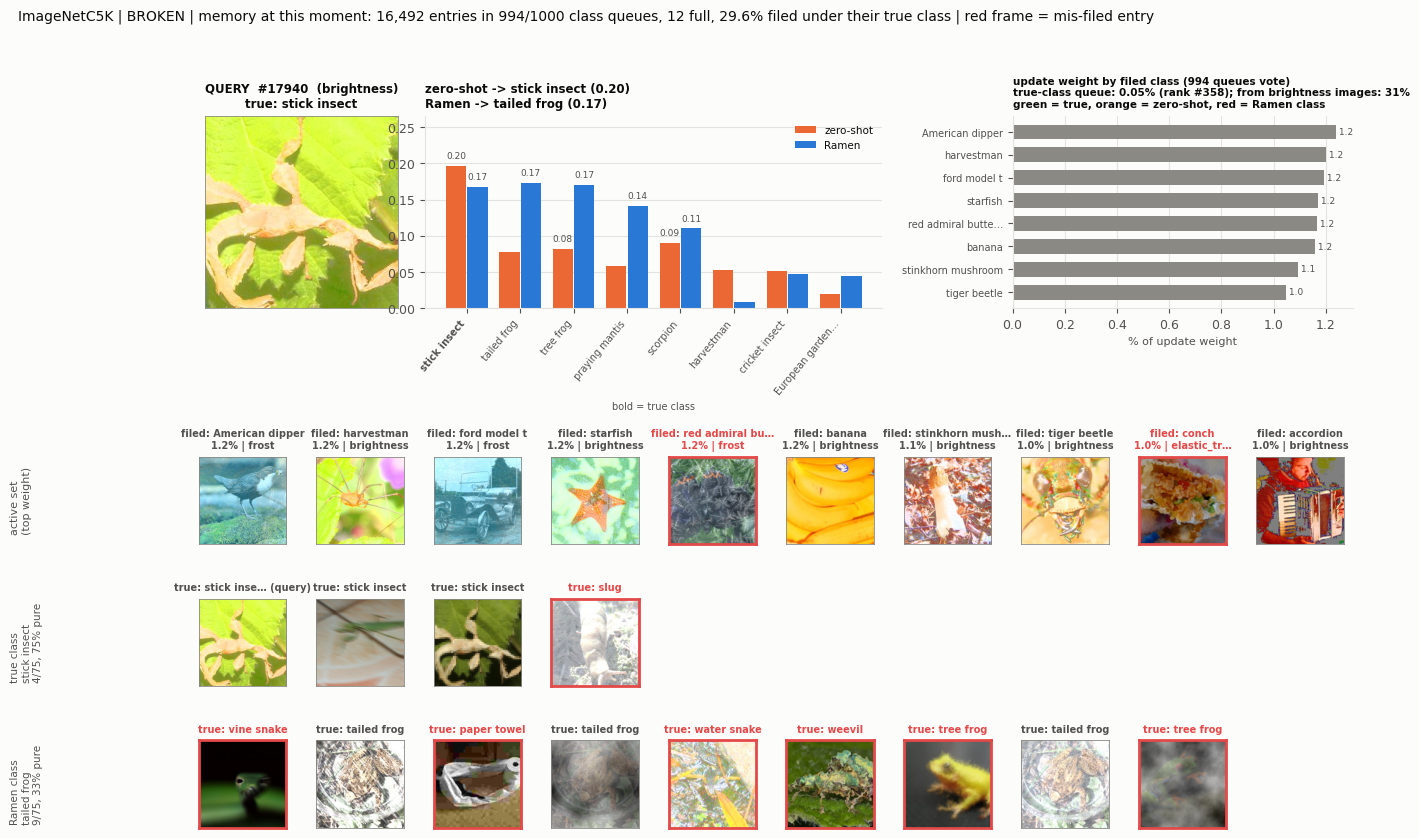

In [24]:
ex.show(broken.position.iloc[1], states);

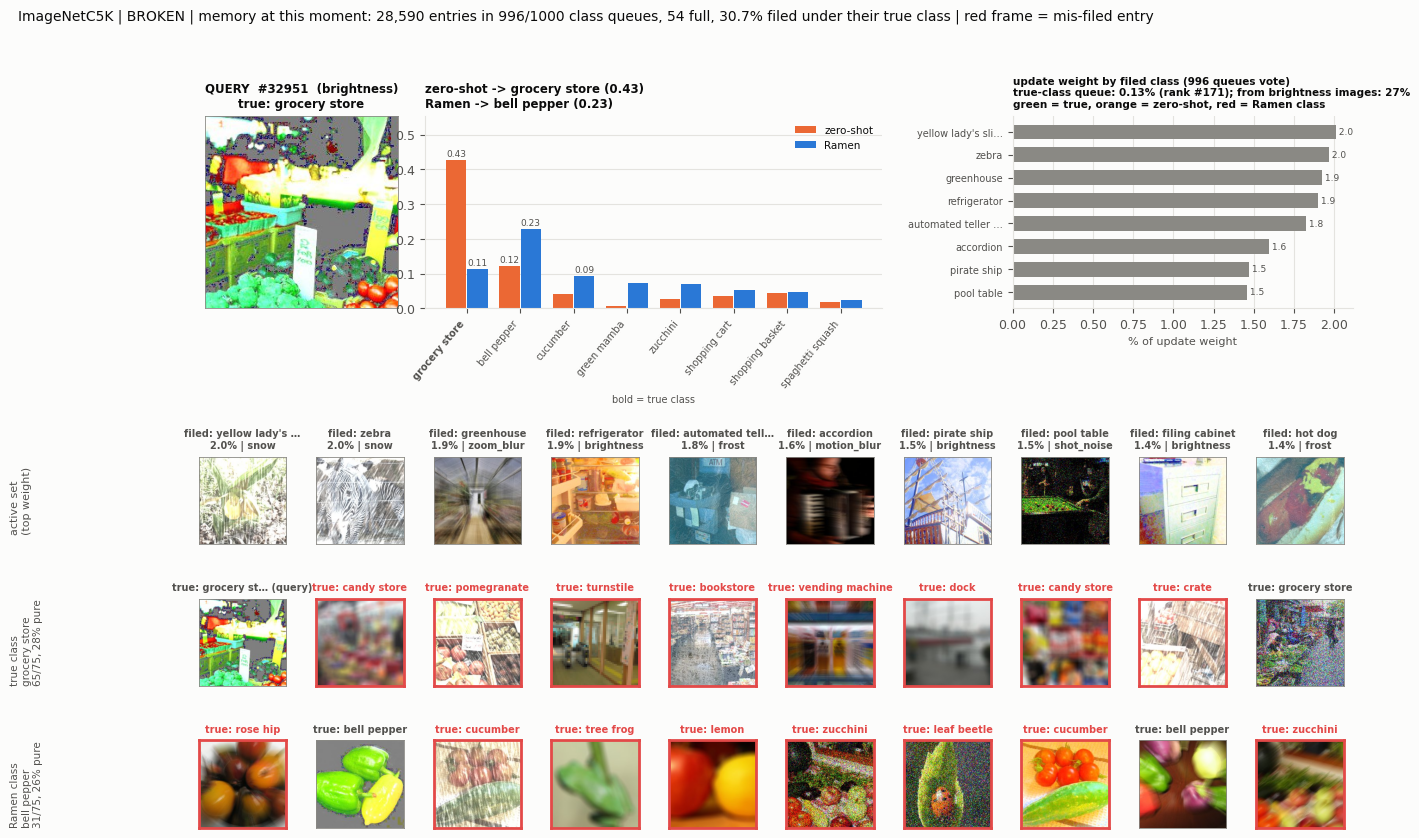

In [25]:
ex.show(broken.position.iloc[2], states);

**Broken examples (brightness):** All three are near-ties that tip toward a semantic neighbour:
- academic gown 0.46 / graduation cap 0.38 -> 0.44 / 0.47;
- Irish Terrier -> Airedale Terrier, where the Irish Terrier queue is only 20% pure and holds other terriers and hounds;
- valley -> rock beauty fish, where the mass spreads to fish and birds and the Ramen-class queue is only 10% pure (noisy textures).

As in the fixed cases, the active set is a mixture of unrelated classes from several corruptions (brightness, frost, fog). Only 28-35% of the weight comes from brightness itself, below the 44% average. So brightness, already the easiest corruption (57% zero-shot), gets a less corruption-specific step, and that step mostly reshuffles fine-grained near-ties.

## Summary (ImageNet-C, seed 0)
- Ramen helps on all 15 corruptions: most on contrast (+10.7, fixes 4.9 samples per one it breaks), least on brightness (+0.9, 1.2 fixed per broken).
- Ramen's update on ImageNet-C is a **corruption-level** correction, not a class-level one. The active set draws ~44% of its weight from same-corruption images (7% of memory) and <1% from the true class's queue. That is why it helps most where zero-shot CLIP is worst: those features need the most correcting.
- **Failures are low-margin zero-shot hits** that tip to a fine-grained neighbour (gown -> cap, Irish -> Airedale Terrier). Neither the memory nor the active set looks different for them. To prevent them, a method needs a per-sample signal about the zero-shot margin and the near-tie class, not a cleaner memory (consistent with the dead ends in the anchor/purity experiments).
- Caveat: an entry's weight is its share of the weighted gradient sum, but Ramen takes the **sign** of that sum (SignSGD). The weights say which entries count, not how much each one moves the prediction.